# 05 · Pipeline completo, evaluación y producción

**Objetivo:** dejar un objeto `PipelineRAG` reutilizable (el de `src/rag_utils.py`),
medir fidelidad y latencia por etapa, jugar con los **mandos** (tamaño de
*chunk*, *k*) y apuntar lo que cambia cuando esto sale del cuaderno y entra en
un servicio: base vectorial, caché, monitorización, evaluación continua y
guardarraíles.

Si ya ejecutaste el cuaderno 04, reutilizamos sus ejemplos de generación. La
búsqueda de hiperparámetros de recuperación **no necesita el LLM** y se puede
repetir barato.


In [1]:
from pathlib import Path
import os, sys, json, time, gc, textwrap

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def _raiz():
    aqui = Path.cwd().resolve()
    for cand in [aqui, *aqui.parents]:
        if (cand / "src" / "rag_utils.py").exists() and (cand / "notebooks").is_dir():
            return cand
    raise FileNotFoundError(
        "No encuentro la raiz del proyecto de RAG "
        "(src/rag_utils.py + notebooks/)."
    )

RAIZ = _raiz()
sys.path.insert(0, str(RAIZ / "src"))

from rag_utils import (
    preparar_rutas,
    fijar_semilla,
    dispositivo,
    configurar_proxy_y_hf,
    comprobar_entorno,
    probar_conexion_hf,
    texto_ayuda_proxy,
    modo_rapido,
    guardar_json,
    cargar_json,
    cargar_corpus,
    cargar_preguntas,
    fragmentar_documentos,
    resumen_fragmentos,
    Codificador,
    similitud_coseno,
    IndiceNumpy,
    IndiceFAISS,
    IndiceBM25,
    fusion_rrf,
    Reranker,
    evaluar_recuperacion,
    construir_mensajes,
    construir_contexto,
    GeneradorLocal,
    contiene_hechos,
    parece_abstencion,
    PipelineRAG,
    evaluar_fidelidad,
    MODELO_EMBEDDINGS_DEFECTO,
    MODELO_RERANKER_DEFECTO,
    MODELO_LLM_DEFECTO,
    MODELO_LLM_RESERVA,
)

try:
    get_ipython().run_line_magic("matplotlib", "inline")
except Exception:
    import matplotlib
    matplotlib.use("Agg")

plt.rcParams.update({
    "figure.figsize": (8, 4.2),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.titlesize": 12,
    "figure.dpi": 110,
})

RUTAS = preparar_rutas(RAIZ)
SEMILLA = fijar_semilla()
CFG_RED = configurar_proxy_y_hf(RAIZ, verbose=True)
DEVICE = dispositivo()
MODO_RAPIDO = modo_rapido(True)
print(f"Raiz:        {RAIZ}")
print(f"Dispositivo: {DEVICE}")
print(f"Semilla:     {SEMILLA}")
print(f"Modo rapido: {MODO_RAPIDO}")


Configuración de red y Hugging Face
  HTTP_PROXY definido:  False
  HTTPS_PROXY definido: False
  NO_PROXY definido:    False
  Certificado SSL (SSL_CERT_FILE / REQUESTS_CA_BUNDLE): False
  Token de Hugging Face presente: False (no se muestra el valor)
  HF_HOME: /workspace/rag/cache-hf
  Modo offline HF: False
  No hizo falta ajustar variables: ya estaban definidas.
Raiz:        /workspace/rag
Dispositivo: cpu
Semilla:     42
Modo rapido: True


In [2]:
# --- Mandos de este cuaderno ---
MODELO_EMB = MODELO_EMBEDDINGS_DEFECTO
K = 4
MAX_NUEVOS = 64 if MODO_RAPIDO else 120
CARGAR_LLM = True          # pon False si solo quieres el estudio de chunking / k
print(f"k={K}  max_nuevos={MAX_NUEVOS}  cargar_llm={CARGAR_LLM}")


k=4  max_nuevos=64  cargar_llm=True


## 1. El *pipeline* como un objeto

`PipelineRAG.preguntar(pregunta)` hace recuperación + generación y devuelve
respuesta, fuentes y latencias. Es la unidad que más adelante envolverías en
una ruta HTTP (por ejemplo, la misma API del curso).


In [3]:
documentos = cargar_corpus(RUTAS["corpus"])
preguntas = cargar_preguntas(RUTAS["datos"] / "preguntas.json")
preguntas_hecho = [p for p in preguntas if p.get("tipo") != "no_esta"]
codificador = Codificador(MODELO_EMB, dispositivo_destino=str(DEVICE))
indice = IndiceFAISS.cargar(RUTAS["modelos"] / "indice_faiss")
indice_bm25 = IndiceBM25(indice.fragmentos)

generador = None
if CARGAR_LLM:
    t0 = time.perf_counter()
    generador = GeneradorLocal(MODELO_LLM_DEFECTO, dispositivo_destino=str(DEVICE), reserva=MODELO_LLM_RESERVA)
    print(f"LLM: {generador.nombre}  carga {time.perf_counter()-t0:.1f}s")
else:
    print("LLM no cargado (CARGAR_LLM=False).")

pipeline = PipelineRAG(
    codificador=codificador,
    indice_denso=indice,
    indice_bm25=indice_bm25,
    generador=generador,
    k=K,
    metodo="hibrido",
)

# Recuperación suelta (sin generar): barata y suficiente para inspeccionar fuentes
q_demo = "¿Quién es la DPO de NubeAndina y cuál es la longitud mínima de las contraseñas?"
hits = pipeline.recuperar(q_demo, k=K)
print("Pregunta:", q_demo)
for r in hits:
    print(f"  {r.rango}. {r.puntuacion:.3f}  {r.fragmento.id}")


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

/workspace/rag/src/rag_utils.py:594: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  self.dim = int(self.modelo.get_sentence_embedding_dimension())


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

LLM: Qwen/Qwen2.5-0.5B-Instruct  carga 0.7s
Pregunta: ¿Quién es la DPO de NubeAndina y cuál es la longitud mínima de las contraseñas?
  1. 0.033  nubeandina-datos-y-seguridad::#4
  2. 0.016  nubeandina-datos-y-seguridad::#5
  3. 0.016  curso-reglamento::#3
  4. 0.016  curso-reglamento::#2


In [4]:
if generador is not None:
    out = pipeline.preguntar(q_demo, con_rag=True, max_nuevos=MAX_NUEVOS)
    print("Respuesta:")
    print(out["respuesta"])
    print("\nLatencias (s):", out["latencias_s"])
else:
    print("Sin LLM: se omite la generacion de demostracion.")
    out = None


Respuesta:
La DPO de NubeAndina es Elena Quispe. La longitud mínima de las contraseñas es de 14 caracteres.

Latencias (s): {'recuperacion': 0.0089, 'generacion': 1.5196, 'total': 1.5285}


## 2. Mandos: tamaño de *chunk* y *k*

Cambiamos el troceado y el *k* midiendo solo **recuperación** (*recall@5* y MRR)
sobre el conjunto hecho a mano. Así se ve el recorte de un hecho o el ruido de
un *k* demasiado grande **sin** pagar la generación en cada punto.

Un *k* alto mete más contexto en el *prompt*: aumenta la probabilidad de que el
hecho viaje, pero también el ruido y la latencia del LLM (y, en modelos pequeños,
la distracción).


chunk= 200  n=203  recall@5=1.000  MRR=0.944


chunk= 400  n= 77  recall@5=1.000  MRR=0.907


chunk= 800  n= 37  recall@5=1.000  MRR=0.907


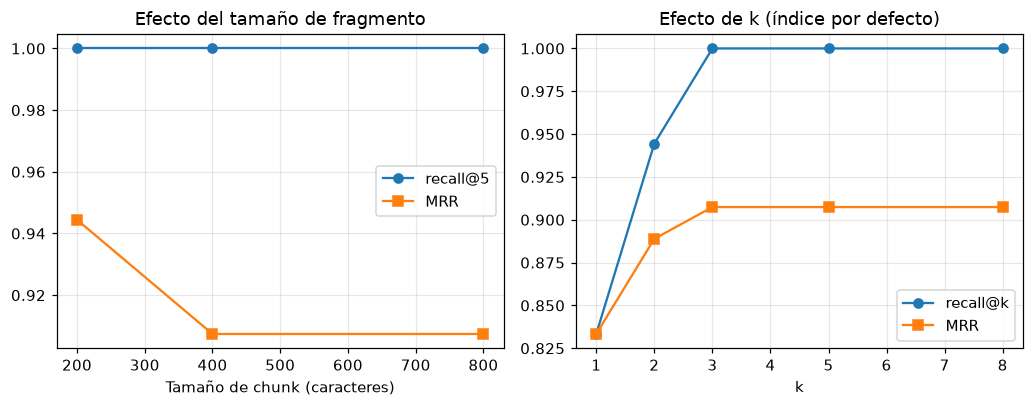

,tamano_chunk,n_fragmentos,recall@5,mrr
0,200,203,1.0,0.944444
1,400,77,1.0,0.907407
2,800,37,1.0,0.907407


In [5]:
def construir_indice(tamano, solape=80, estrategia="solape"):
    frags = fragmentar_documentos(documentos, estrategia=estrategia, tamano=tamano, solape=solape)
    vec = codificador.codificar([f.texto for f in frags], lote=16, progreso=False)
    return IndiceFAISS(vec, frags), frags

filas_chunk = []
for tam in [200, 400, 800]:
    ind, frags = construir_indice(tam, solape=80)
    def _buscador(pregunta, k, _ind=ind):
        qv = codificador.codificar([pregunta], progreso=False)[0]
        return _ind.buscar(qv, k=k)
    ev = evaluar_recuperacion(preguntas_hecho, _buscador, k=5)
    filas_chunk.append({
        "tamano_chunk": tam,
        "n_fragmentos": len(frags),
        "recall@5": ev["recall@5"],
        "mrr": ev["mrr"],
    })
    print(f"chunk={tam:4d}  n={len(frags):3d}  recall@5={ev['recall@5']:.3f}  MRR={ev['mrr']:.3f}")

tabla_chunk = pd.DataFrame(filas_chunk)

# k, con el indice por defecto del cuaderno 02
filas_k = []
def buscador_default(pregunta, k):
    qv = codificador.codificar([pregunta], progreso=False)[0]
    return indice.buscar(qv, k=k)

for k in [1, 2, 3, 5, 8]:
    ev = evaluar_recuperacion(preguntas_hecho, buscador_default, k=k)
    filas_k.append({"k": k, "recall": ev[f"recall@{k}"], "mrr": ev["mrr"]})
tabla_k = pd.DataFrame(filas_k)

fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.8))
axes[0].plot(tabla_chunk["tamano_chunk"], tabla_chunk["recall@5"], marker="o", label="recall@5")
axes[0].plot(tabla_chunk["tamano_chunk"], tabla_chunk["mrr"], marker="s", label="MRR")
axes[0].set_xlabel("Tamaño de chunk (caracteres)")
axes[0].set_title("Efecto del tamaño de fragmento")
axes[0].legend()
axes[1].plot(tabla_k["k"], tabla_k["recall"], marker="o", label="recall@k")
axes[1].plot(tabla_k["k"], tabla_k["mrr"], marker="s", label="MRR")
axes[1].set_xlabel("k")
axes[1].set_title("Efecto de k (índice por defecto)")
axes[1].legend()
fig.tight_layout()
fig.savefig(RUTAS["resultados"] / "fig_mandos_chunk_k.png", dpi=130)
plt.show()
tabla_chunk


## 3. Fidelidad y latencia (si el LLM está cargado)

Releemos `resultados/generacion.json` si existe (cuaderno 04) y, si hay
generador, evaluamos un subconjunto breve para obtener latencias por etapa en
este proceso.


Resultados del cuaderno 04:
  modelo: Qwen/Qwen2.5-0.5B-Instruct
  cobertura media sin RAG: 0.00
  cobertura media con RAG: 0.58
  latencia media con RAG:  31.3 s



Evaluacion breve con RAG: cobertura media=0.61  ok=1/3
Latencia media total: 1.4 s


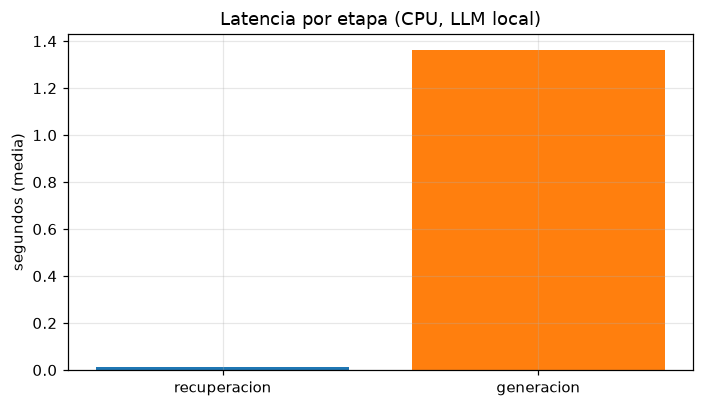

In [6]:
ruta_gen = RUTAS["resultados"] / "generacion.json"
previo = cargar_json(ruta_gen) if ruta_gen.exists() else None
if previo:
    print("Resultados del cuaderno 04:")
    print(f"  modelo: {previo['modelo_llm']}")
    print(f"  cobertura media sin RAG: {previo['cobertura_media_sin']:.2f}")
    print(f"  cobertura media con RAG: {previo['cobertura_media_con']:.2f}")
    print(f"  latencia media con RAG:  {previo['latencia_media_con_s']:.1f} s")

eval_fid = None
if generador is not None:
    ids_eval = ["q11", "q13", "q19"] if MODO_RAPIDO else ["q11", "q13", "q03", "q10", "q19"]
    sub = [p for p in preguntas if p["id"] in ids_eval]
    eval_fid = evaluar_fidelidad(sub, pipeline, con_rag=True, max_nuevos=MAX_NUEVOS, k=K)
    print(f"\nEvaluacion breve con RAG: cobertura media={eval_fid['cobertura_media']:.2f}  ok={eval_fid['n_ok']}/{eval_fid['n']}")
    print(f"Latencia media total: {eval_fid['latencia_media_s']:.1f} s")
    lat_r = [d["latencias_s"]["recuperacion"] for d in eval_fid["detalle"]]
    lat_g = [d["latencias_s"]["generacion"] for d in eval_fid["detalle"]]
    fig, ax = plt.subplots(figsize=(6.5, 3.8))
    ax.bar(["recuperacion", "generacion"], [float(np.mean(lat_r)), float(np.mean(lat_g))], color=["#1f77b4", "#ff7f0e"])
    ax.set_ylabel("segundos (media)")
    ax.set_title("Latencia por etapa (CPU, LLM local)")
    fig.tight_layout()
    fig.savefig(RUTAS["resultados"] / "fig_latencia_etapas.png", dpi=130)
    plt.show()
else:
    print("Sin LLM: no se recalcula fidelidad. Usa los numeros del cuaderno 04.")


## 4. De este cuaderno a producción (notas de MLOps)

Lo que has montado es un RAG mínimo, reproducible en CPU. En un servicio real
cambian, sobre todo, el **sitio** donde vive cada pieza y la **disciplina** con
la que la mides.

**Almacén de vectores.** FAISS en un proceso (o NumPy, en el laboratorio) vale
para un corpus pequeño. Cuando hay muchos documentos, varios servicios y
actualizaciones, entra un almacén: `pgvector` en Postgres, Chroma, Qdrant,
Vertex AI Vector Search, OpenSearch, etc. El contrato no cambia: guardas
vectores + metadatos (identificador, documento, fechas, permisos) y preguntas
por los k más cercanos.

**Actualización del índice.** Si el reglamento cambia el viernes, el índice del
jueves está mal. Hace falta una tubería que detecte documentos nuevos o
editados, los vuelva a trocear y los upsert-e. Versiona el corpus y el índice
como versionas un modelo.

**Caché.** Las preguntas repetidas («¿cuál es el puerto de la API?») no deberían
volver a embeberse ni a llamarse al LLM cada vez. Se cachea el embedding de la
consulta, y a veces la respuesta, con una caducidad ligada a la versión del
índice.

**Evaluación continua.** El `preguntas.json` de este taller es un *golden set*
en miniatura. En producción se mantiene un conjunto vivo: *recall@k*, cobertura
de hechos, tasa de abstención, *feedback* de usuarios (pulgar abajo) y, si se
quiere, métricas tipo fidelidad/relevancia con un juez (otro modelo o un
humano). Un cambio de *chunk*, de *k* o de modelo se acepta o se rechaza con
esas cifras, no a ojo.

**Latencia y coste.** Recupera en milisegundos; genera en cientos de
milisegundos o en segundos (como has visto en CPU). Mide por etapa. Un modelo
por API será más capaz y más caro; el contexto que le envías sigue siendo tu
responsabilidad (y tu factura, porque pagas tokens de *prompt*).

**Guardarraíles.** «Responde solo con el contexto» es el primero. Otros: no
exfiltrar secretos, no obedecer instrucciones escondidas **dentro de un
documento** (*prompt injection*), filtrar PII, limitar temas, registrar la
fuente de cada afirmación. El corpus de NubeAndina prohíbe mandar datos reales
de cooperativas a una API pública: esa norma también es un guardarraíl de diseño.

**Observabilidad.** Logs con el identificador de la pregunta, los fragmentos
servidos, el modelo, las latencias y un hash del *prompt*. Sin eso, un fallo en
producción («desde el martes responde mal») no se diagnostica.

**No es la única pieza.** RAG convive con el registro de modelos (MLflow, alias
`champion`), con el contenedor (`retencion-api:local`), con CI y con un
despliegue que se pueda revertir. El recuperador y el generador también son
modelos: se promocionan, se miden y se retiran como el resto.


In [7]:
guardar_json(
    {
        "k": K,
        "estudio_chunk": filas_chunk,
        "estudio_k": filas_k,
        "generacion_previa": {
            "cobertura_media_sin": previo["cobertura_media_sin"] if previo else None,
            "cobertura_media_con": previo["cobertura_media_con"] if previo else None,
            "modelo_llm": previo["modelo_llm"] if previo else None,
        } if previo else None,
        "fidelidad_breve": (
            {
                "n": eval_fid["n"],
                "cobertura_media": eval_fid["cobertura_media"],
                "n_ok": eval_fid["n_ok"],
                "latencia_media_s": eval_fid["latencia_media_s"],
            }
            if eval_fid is not None else None
        ),
    },
    RUTAS["resultados"] / "pipeline.json",
)
print("Metricas escritas en resultados/pipeline.json")
print("Siguiente cuaderno: 06-ejercicios.")


Metricas escritas en resultados/pipeline.json
Siguiente cuaderno: 06-ejercicios.


## Recapitulando

- El *pipeline* es una función: pregunta entra, respuesta + fuentes + latencias salen.
- *Chunk* y *k* se afinan con un *golden set* de recuperación, no solo «a ojo».
- En producción, el problema deja de ser el cuaderno y pasa a ser el ciclo de
  vida: índice, evaluación, caché, guardarraíles y despliegue.

Siguiente: [06-ejercicios.ipynb](06-ejercicios.ipynb).
